<a href="https://colab.research.google.com/github/Series-Parallel/Machine_in_control/blob/main/cartpole_pid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

I built a simulated cart with a pole on top to understand PID control properly, and played with the P, I and D knobs one at a time to see what each one does. Then I asked one question: if I tune a controller on a perfect simulated robot, does it still work when the robot is a bit different? I made 500 randomly changed robots (different weights, pole length, motor strength, a delay on the sensor and some noise) and tested four controllers on them.

The same PID, tuned by the same program, kept the pole up on 43% of them when it only practiced on the perfect robot, and on 99% when it practiced on randomly changed ones. The perfect-robot version failed on every robot with a sensor delay of 15 ms or more. LQR also did well (98%). It's all simulation, and the test robots are random in the same way as the practice ones, so I can't say how it would handle something really different.

In [2]:
# ---- Cell 1: cart-pole dynamics (plain NumPy) ----
# State s = [x, x_dot, theta, theta_dot]; theta = 0 is UPRIGHT (unstable), positive = leaning right.
# Input F = horizontal force on the cart (N), positive = push right.
# Lagrangian derivation gives (l = half pole length, point-mass-like pole on a rigid rod):
#   temp      = (F + m*l*th_dot^2*sin(th)) / (M+m)
#   th_ddot   = (g*sin(th) - cos(th)*temp) / (l*(4/3 - m*cos(th)^2/(M+m)))
#   x_ddot    = temp - m*l*th_ddot*cos(th)/(M+m)
import numpy as np
import matplotlib.pyplot as plt

class CartPole:
    def __init__(self, M=1.0, m=0.1, l=0.5, g=9.81, dt=0.005):
        self.M, self.m, self.l, self.g, self.dt = M, m, l, g, dt

    def deriv(self, s, F):
        x, xd, th, thd = s
        M, m, l, g = self.M, self.m, self.l, self.g
        sin, cos = np.sin(th), np.cos(th)
        temp = (F + m * l * thd**2 * sin) / (M + m)
        thdd = (g * sin - cos * temp) / (l * (4/3 - m * cos**2 / (M + m)))
        xdd = temp - m * l * thdd * cos / (M + m)
        return np.array([xd, xdd, thd, thdd])

    def step(self, s, F):
        """One RK4 step (force held constant over dt, like a zero-order-hold controller)."""
        dt = self.dt
        k1 = self.deriv(s, F)
        k2 = self.deriv(s + 0.5*dt*k1, F)
        k3 = self.deriv(s + 0.5*dt*k2, F)
        k4 = self.deriv(s + dt*k3, F)
        return s + dt/6 * (k1 + 2*k2 + 2*k3 + k4)

# Sanity check: with no control, a 0.05 rad tilt must fall over (upright is unstable).
cp = CartPole(); s = np.array([0, 0, 0.05, 0.0])
for _ in range(int(1.0/cp.dt)): s = cp.step(s, 0.0)
print(f"No control, after 1 s: theta = {s[2]:.2f} rad (started at 0.05) -> falls, as expected")

No control, after 1 s: theta = 1.26 rad (started at 0.05) -> falls, as expected


In [3]:
# ---- Cell 2: PID controller class ----
class PID:
    """PID on the pole angle with:
       - derivative on MEASUREMENT (no 'kick' when the setpoint changes)
       - low-pass filtered derivative (tames sensor noise; tau = filter time constant)
       - anti-windup by clamping the integrator (limits the I term's contribution)
       - output saturation (a real motor cannot push infinitely hard)"""
    def __init__(self, kp, ki, kd, dt, u_max=30.0, i_max=10.0, tau=0.01):
        self.kp, self.ki, self.kd, self.dt = kp, ki, kd, dt
        self.u_max, self.i_max, self.tau = u_max, i_max, tau
        self.reset()

    def reset(self):
        self.i_term, self.prev_meas, self.d_filt = 0.0, None, 0.0

    def __call__(self, meas, setpoint=0.0):
        # Sign: angle is positive when the pole leans right -> push the cart right (same sign),
        # so error = meas - setpoint (direct-acting loop).
        err = meas - setpoint
        self.i_term = np.clip(self.i_term + self.ki * err * self.dt, -self.i_max, self.i_max)
        raw_d = 0.0 if self.prev_meas is None else (meas - self.prev_meas) / self.dt
        a = self.dt / (self.tau + self.dt)
        self.d_filt += a * (raw_d - self.d_filt)
        self.prev_meas = meas
        u = self.kp * err + self.i_term + self.kd * self.d_filt
        return float(np.clip(u, -self.u_max, self.u_max))

In [4]:
# ---- Cell 3: closed-loop simulation ----
def simulate(pid, th0=0.1, T=5.0, noise_std=0.0, push=None, seed=0, plant=None):
    """push = (time_s, force_N, duration_s) optional disturbance on the cart.
    Returns log with columns: t, x, theta, theta_dot, F, fell."""
    rng = np.random.default_rng(seed)
    cp = plant or CartPole()
    pid.reset()
    s = np.array([0.0, 0.0, th0, 0.0])
    n = int(T / cp.dt)
    log = np.zeros((n, 6))
    fell = False
    for k in range(n):
        t = k * cp.dt
        meas = s[2] + rng.normal(0, noise_std)
        F = pid(meas)
        Fd = F
        if push and push[0] <= t < push[0] + push[2]: Fd += push[1]
        s = cp.step(s, Fd)
        if abs(s[2]) > np.pi/4: fell = True   # > 45 deg: call it fallen
        log[k] = [t, s[0], s[2], s[3], F, fell]
        if fell: log = log[:k+1]; break
    return log

In [5]:
# ---- Cell 4: performance metrics ----
def metrics(log, tol=0.02):
    t, th, F = log[:, 0], log[:, 2], log[:, 4]
    fell = bool(log[-1, 5])
    outside = np.where(np.abs(th) > tol)[0]
    settle = np.nan if fell else (t[outside[-1]] if len(outside) else 0.0)
    return dict(fell=fell, settling_time_s=settle,
                max_angle_rad=float(np.max(np.abs(th))), effort_rms_N=float(np.sqrt(np.mean(F**2))))

In [ ]:
# ---- Cell 5: baseline run (PID kp=100, ki=1, kd=20, start tilted 0.1 rad) ----
pid = PID(kp=100, ki=1, kd=20, dt=0.005)
log = simulate(pid, th0=0.1)
print(metrics(log))

{'fell': False, 'settling_time_s': np.float64(0.335), 'max_angle_rad': 0.09983779705300057, 'effort_rms_N': 0.7163791805273625}


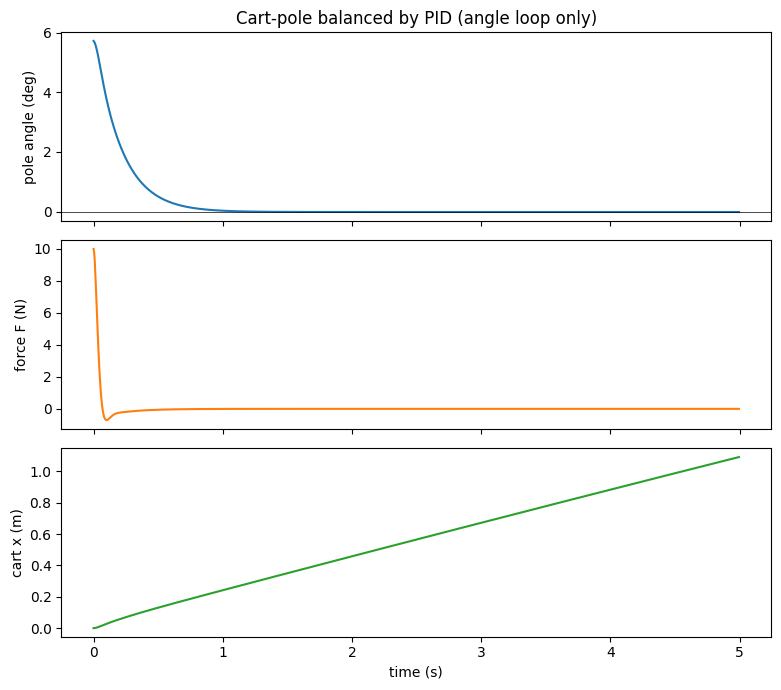

In [ ]:
# ---- Cell 6: response plots for the baseline run ----
fig, ax = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
ax[0].plot(log[:, 0], np.degrees(log[:, 2])); ax[0].set_ylabel("pole angle (deg)"); ax[0].axhline(0, c="k", lw=.5)
ax[1].plot(log[:, 0], log[:, 4], c="C1"); ax[1].set_ylabel("force F (N)")
ax[2].plot(log[:, 0], log[:, 1], c="C2"); ax[2].set_ylabel("cart x (m)"); ax[2].set_xlabel("time (s)")
ax[0].set_title("Cart-pole balanced by PID (angle loop only)")
plt.tight_layout(); plt.show()

#### uptill now it was all coding stuff to configuring the pid into the code so I can like do experiments and understand exactly what is happening behind the scenes. Now we will see some animation to understand easily what is actually happening!


In [ ]:
# ---- Cell 7: live animation (Python simulates, the browser draws it smoothly) ----
import json, uuid
from IPython.display import HTML

_TEMPLATE = """
<div style="font-family:monospace">
<canvas id="c__ID__" width="640" height="260" style="border:1px solid #888;border-radius:6px"></canvas>
<canvas id="p__ID__" width="340" height="260" style="border:1px solid #888;border-radius:6px"></canvas>
</div>
<script>
(function(){
  const D = __DATA__;
  const c = document.getElementById("c__ID__"), p = document.getElementById("p__ID__");
  if (!c || !p) return;
  const g = c.getContext("2d"), q = p.getContext("2d");
  const W = c.width, H = c.height, n = D.t.length, T = D.t[n-1], L = D.L;
  const xmin = Math.min(-1.5, Math.min(...D.x) - 1), xmax = Math.max(1.5, Math.max(...D.x) + 1);
  const sc = Math.min(W / (xmax - xmin), (H - 90) / (L + 0.4)), gy = H - 55;
  const X = v => (v - xmin) * sc;
  const deg = D.th.map(a => a * 180 / Math.PI);
  const maxdeg = Math.max(10, ...deg.map(Math.abs));
  const PW = p.width, PH = p.height, ml = 42;
  const PX = t => ml + (PW - ml - 12) * t / T, PY = d => PH / 2 - (PH / 2 - 28) * d / maxdeg;

  function frame(i, done) {
    // left: cart and pole
    g.clearRect(0, 0, W, H);
    g.strokeStyle = "#888"; g.lineWidth = 2; g.beginPath(); g.moveTo(0, gy); g.lineTo(W, gy); g.stroke();
    g.setLineDash([4, 6]); g.beginPath(); g.moveTo(X(0), gy - 8); g.lineTo(X(0), gy + 8); g.stroke(); g.setLineDash([]);
    const cx = X(D.x[i]), cw = 0.4 * sc, ch = 0.2 * sc;
    g.fillStyle = "#378ADD"; g.fillRect(cx - cw / 2, gy - ch, cw, ch);
    const px = cx + L * sc * Math.sin(D.th[i]), py = gy - ch - L * sc * Math.cos(D.th[i]);
    g.strokeStyle = "#D85A30"; g.lineWidth = 6; g.lineCap = "round";
    g.beginPath(); g.moveTo(cx, gy - ch); g.lineTo(px, py); g.stroke();
    g.fillStyle = "#D85A30"; g.beginPath(); g.arc(px, py, 9, 0, 7); g.fill();
    const fx = D.F[i] * 0.03 * sc;                       // orange bar = how hard the motor pushes
    g.strokeStyle = "#EF9F27"; g.lineWidth = 8; g.lineCap = "butt";
    g.beginPath(); g.moveTo(cx, gy + 22); g.lineTo(cx + fx, gy + 22); g.stroke();
    g.fillStyle = "#888"; g.font = "13px monospace";
    g.fillText("t=" + D.t[i].toFixed(2) + "s  angle=" + deg[i].toFixed(1) + "deg  force=" + D.F[i].toFixed(1) + "N", 10, 20);
    g.fillText("blue dashed tick = start position, orange bar = motor push", 10, H - 8);
    if (D.fell && done) { g.fillStyle = "#E24B4A"; g.font = "bold 28px sans-serif"; g.fillText("FELL OVER", W / 2 - 80, 60); }

    // right: pole angle over time with moving dot
    q.clearRect(0, 0, PW, PH);
    q.strokeStyle = "#888"; q.lineWidth = 1;
    q.beginPath(); q.moveTo(ml, PY(0)); q.lineTo(PW - 12, PY(0)); q.stroke();
    q.beginPath(); q.moveTo(ml, 10); q.lineTo(ml, PH - 20); q.stroke();
    q.fillStyle = "#888"; q.font = "12px monospace";
    q.fillText("+" + maxdeg.toFixed(0), 4, 24); q.fillText("-" + maxdeg.toFixed(0), 4, PH - 24);
    q.fillText("pole angle (deg) vs time", ml + 6, 14); q.fillText("0", 28, PY(0) + 4); q.fillText(T.toFixed(1) + "s", PW - 38, PH - 6);
    q.strokeStyle = "#378ADD"; q.lineWidth = 2; q.beginPath();
    for (let k = 0; k < n; k++) { const x = PX(D.t[k]), y = PY(deg[k]); k ? q.lineTo(x, y) : q.moveTo(x, y); }
    q.stroke();
    q.fillStyle = "#D85A30"; q.beginPath(); q.arc(PX(D.t[i]), PY(deg[i]), 5, 0, 7); q.fill();
  }

  const t0 = performance.now();
  function tick(now) {
    if (!document.body.contains(c)) return;                 // output was replaced: stop
    const tt = ((now - t0) / 1000) % (T + 1.0);             // loop with a 1 s pause at the end
    const done = tt >= T;
    frame(Math.min(n - 1, Math.floor(tt / (T / (n - 1)))), done);
    requestAnimationFrame(tick);
  }
  requestAnimationFrame(tick);
})();
</script>
"""

def animate_run(log, l=0.5, every=2):
    """log from simulate(); every=2 -> one animation frame per 0.01 s of simulated time."""
    idx = np.unique(np.append(np.arange(0, len(log), every), len(log) - 1))
    data = dict(t=log[idx, 0].round(4).tolist(), x=log[idx, 1].round(4).tolist(),
                th=log[idx, 2].round(5).tolist(), F=log[idx, 4].round(3).tolist(),
                L=2 * l, fell=bool(log[-1, 5]))
    return HTML(_TEMPLATE.replace("__ID__", uuid.uuid4().hex[:8]).replace("__DATA__", json.dumps(data)))

In [ ]:
# ---- Cell 8: interactive controls: the animation updates while you drag a slider ----
import ipywidgets as w
from IPython.display import display

opts = dict(continuous_update=True, style={"description_width": "150px"}, layout=w.Layout(width="520px"))
kp    = w.FloatSlider(value=100, min=0,    max=200, step=1,     description="Kp  (P: react to lean)", **opts)
ki    = w.FloatSlider(value=1,   min=0,    max=50,  step=0.5,   description="Ki  (I: react to time)", **opts)
kd    = w.FloatSlider(value=20,  min=0,    max=60,  step=0.5,   description="Kd  (D: react to speed)", **opts)
th0   = w.FloatSlider(value=0.1, min=-0.3, max=0.3, step=0.01,  description="start tilt (rad)", **opts)
noise = w.FloatSlider(value=0.0, min=0,    max=0.05, step=0.002, description="sensor noise (rad)", **opts)
umax  = w.FloatSlider(value=30,  min=2,    max=60,  step=1,     description="motor limit (N)", **opts)
shove = w.FloatSlider(value=0,   min=-30,  max=30,  step=1,     description="shove at t=2 s (N)", **opts)
dur   = w.FloatSlider(value=20,  min=5,    max=30,  step=1,     description="run length (s)", **opts)

def show(kp, ki, kd, th0, noise, umax, shove, dur):
    pid = PID(kp, ki, kd, dt=0.005, u_max=umax)
    log = simulate(pid, th0=th0, T=dur, noise_std=noise, push=(2.0, shove, 0.1) if shove else None)
    m = metrics(log)
    print("RESULT:", "FELL OVER" if m["fell"] else f"stayed up, settled in {m['settling_time_s']:.2f} s",
          f"| max tilt {np.degrees(m['max_angle_rad']):.1f} deg | motor effort (rms) {m['effort_rms_N']:.1f} N")
    display(animate_run(log, every=2 if dur <= 10 else 4))

out = w.interactive_output(show, dict(kp=kp, ki=ki, kd=kd, th0=th0, noise=noise, umax=umax, shove=shove, dur=dur))
display(w.VBox([kp, ki, kd, th0, noise, umax, shove, dur]), out)

Output()

### So let me write about what I understood for PID.

1. So P (proportional) is basically the is how far the thing is from its orginal state, like it will steer harder the more the thing is off from its orginal state.
2. Then comes the I (integral), it is the leaning (or the amount of "off") from original state so far. Like it is supposed to fixed the so far aggregated lean by the P.
3. The comes the D (derivative) D is the brake: it looks at how fast the pole is moving and pushes against that, so the pole doesn't swing past upright. But it has its certain turning as well, if u do not provide the brake (d) the pole will start to wiggle and eventually fall. If u give a lot of brake it will take time to get steady, and if U put it in just right amount it will overshoot only once and then gets steady!


In [6]:
# ---- Cell 9: helpers for the gain experiments (sweep one knob, plot all runs, print a score table) ----
COLS = {"angle": (2, "pole angle (deg)", np.degrees),
        "force": (4, "motor force (N)", lambda v: v),
        "cart":  (1, "cart position (m)", lambda v: v)}

def sweep(name, values, base, T=5.0, th0=0.1, noise=0.0, push=None, umax=30.0):
    """Run the same scenario several times, changing ONE controller setting (name) over `values`."""
    runs = []
    for v in values:
        p = {**base, name: v}
        pid = PID(p["kp"], p["ki"], p["kd"], dt=0.005, u_max=umax, i_max=p.get("i_max", 10.0))
        log = simulate(pid, th0=th0, T=T, noise_std=noise, push=push)
        runs.append((f"{name}={v}", log))
    return runs

def plot_runs(runs, title, rows=("angle", "force")):
    fig, axes = plt.subplots(len(rows), 1, figsize=(9, 3.1 * len(rows)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, r in zip(axes, rows):
        col, ylabel, f = COLS[r]
        for k, (label, log) in enumerate(runs):
            ax.plot(log[:, 0], f(log[:, col]), c=f"C{k}", label=label)
            if log[-1, 5]: ax.plot(log[-1, 0], f(log[-1, col]), "x", c=f"C{k}", ms=10, mew=3)   # X = fell
        ax.set_ylabel(ylabel); ax.axhline(0, c="k", lw=.5)
    axes[0].set_title(title); axes[0].legend(ncol=len(runs), fontsize=8); axes[-1].set_xlabel("time (s)")
    plt.tight_layout(); plt.show()

def score_table(runs):
    print(f"{'run':<12}{'fell?':<8}{'settle (s)':<12}{'max tilt (deg)':<16}{'effort rms (N)':<16}")
    for label, log in runs:
        m = metrics(log)
        print(f"{label:<12}{('YES' if m['fell'] else 'no'):<8}{m['settling_time_s']:<12.2f}"
              f"{np.degrees(m['max_angle_rad']):<16.1f}{m['effort_rms_N']:<16.1f}")

## Experiment 1: the P knob (Kp)

Change only Kp (Ki=1, Kd=20 fixed). Start tilt 0.1 rad. An **X** marks a run where the pole fell.

**What P does:** it pushes in proportion to the lean. Too weak and the cart cannot catch the pole; stronger pulls the pole back faster.

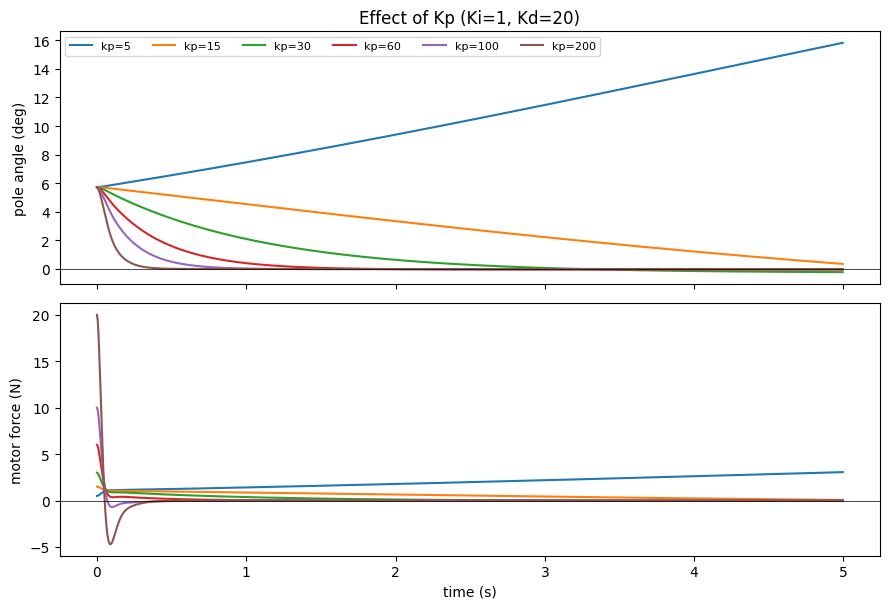

run         fell?   settle (s)  max tilt (deg)  effort rms (N)  
kp=5        no      5.00        15.8            2.1             
kp=15       no      4.08        5.7             0.6             
kp=30       no      1.54        5.7             0.4             
kp=60       no      0.62        5.7             0.5             
kp=100      no      0.34        5.7             0.7             
kp=200      no      0.14        5.7             1.5             


In [ ]:
# ---- Cell 11: Experiment 1, sweep Kp ----
base = dict(kp=100, ki=1, kd=20)
runs = sweep("kp", [5, 15, 30, 60, 100, 200], base)
plot_runs(runs, "Effect of Kp (Ki=1, Kd=20)")
score_table(runs)

## Experiment 2: the D knob (Kd)

Change only Kd (Kp=100, Ki=1 fixed). Start tilt 0.1 rad. An **X** marks a run where the pole fell. The runs are 15 s long (a shorter run hides a slow failure).

**What D does:** it reacts to how *fast* the pole is moving and pushes against that motion, so it acts as a brake that damps the swing. Too little and the pole overshoots and wobbles, and with no D at all the wobble grows until the pole falls (about 11 s here). Enough D and it settles smoothly.

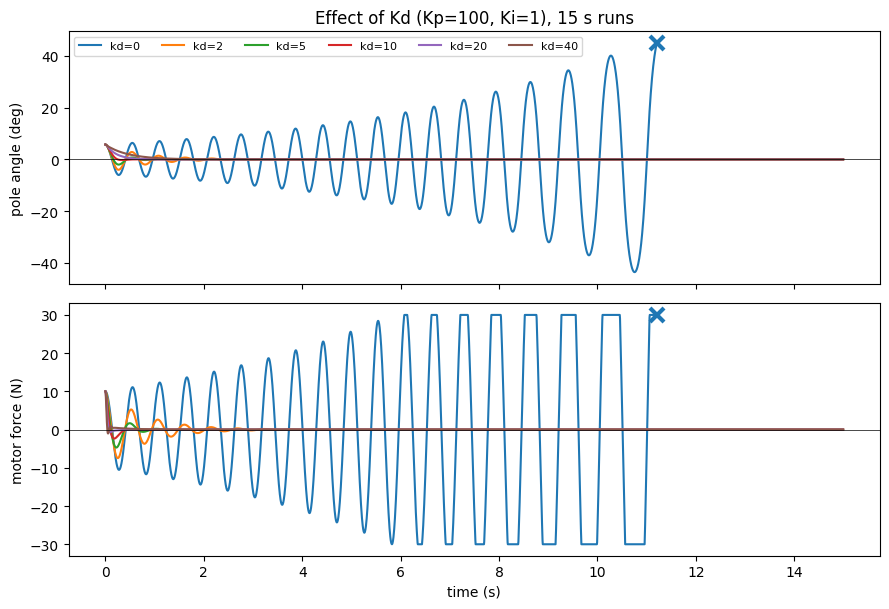

run         fell?   settle (s)  max tilt (deg)  effort rms (N)  
kd=0        YES     nan         45.0            20.4            
kd=2        no      1.13        5.7             1.2             
kd=5        no      0.35        5.7             0.7             
kd=10       no      0.17        5.7             0.5             
kd=20       no      0.34        5.7             0.4             
kd=40       no      0.70        5.7             0.4             


In [7]:
# ---- Cell 13: Experiment 2, sweep Kd (15 s, so a slow failure such as Kd=0 shows up) ----
base = dict(kp=100, ki=1, kd=20)
runs = sweep("kd", [0, 2, 5, 10, 20, 40], base, T=15.0)
plot_runs(runs, "Effect of Kd (Kp=100, Ki=1), 15 s runs")
score_table(runs)

## Experiment 3: the I knob (Ki)

Change only Ki (Kp=100, Kd=20 fixed). The pole starts upright, and a constant 2 N wind pushes the cart for the whole 10 s run.

**What I does:** it adds up the leftover lean over time. With P and D alone, the pole settles slightly tilted, because the controller needs some lean to push back against the wind. I removes that leftover tilt, but a large Ki overshoots and swings.

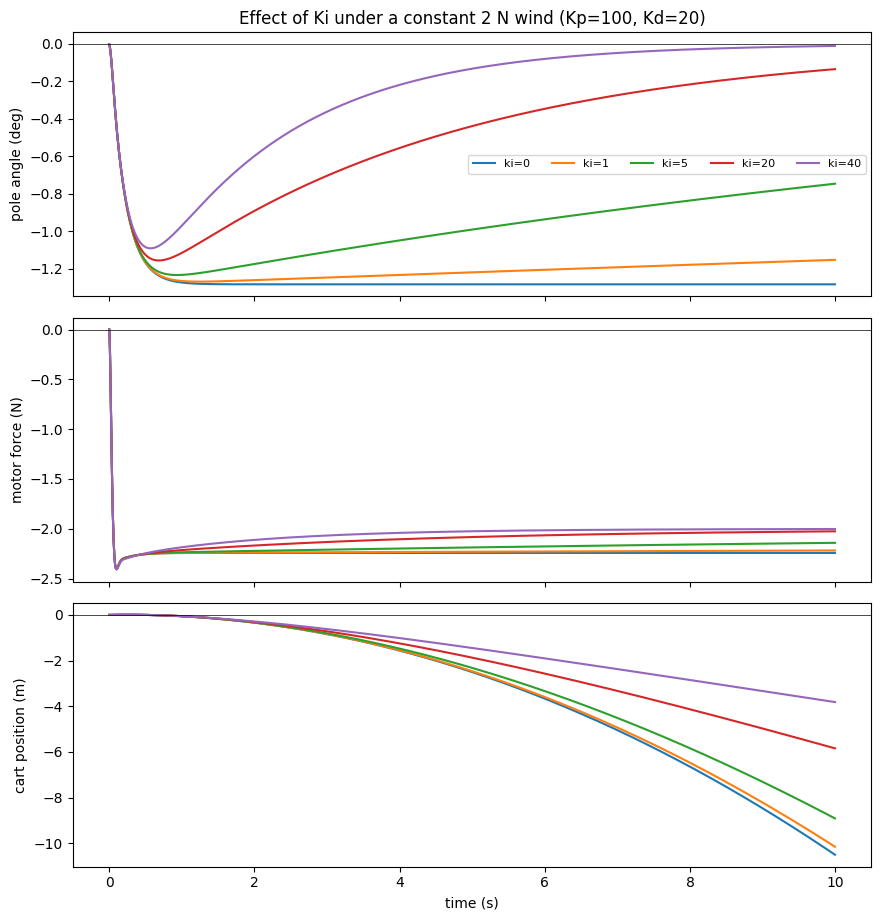

run       fell?   final angle (deg)   peak angle (deg)  
ki=0      no      -1.28               1.28              
ki=1      no      -1.16               1.27              
ki=5      no      -0.77               1.23              
ki=20     no      -0.15               1.16              
ki=40     no      -0.01               1.09              


In [ ]:
# ---- Cell 15: Experiment 3, sweep Ki under a constant 2 N wind ----
base = dict(kp=100, ki=1, kd=20)
wind = (0.0, 2.0, 10.0)                       # (start time, force in N, duration in s): constant push on the cart
runs = sweep("ki", [0, 1, 5, 20, 40], base, T=10.0, th0=0.0, push=wind)
plot_runs(runs, "Effect of Ki under a constant 2 N wind (Kp=100, Kd=20)", rows=("angle", "force", "cart"))

print(f"{'run':<10}{'fell?':<8}{'final angle (deg)':<20}{'peak angle (deg)':<18}")
for label, log in runs:
    last = log[log[:, 0] > log[-1, 0] - 1.0]                 # average over the last second
    print(f"{label:<10}{('YES' if log[-1, 5] else 'no'):<8}{np.degrees(last[:, 2].mean()):<20.2f}{np.degrees(np.abs(log[:, 2]).max()):<18.2f}")

## Experiment 4: sensor noise and the D knob

Sensor noise 0.01 rad (about 0.6 degrees) is added to the angle the controller reads. Change only Kd (Kp=100, Ki=1 fixed).

**What to look at:** the *motor force* graph. D divides the change between two readings by a tiny time step, so it multiplies noise by about 200. A bigger Kd means more jitter in the motor force, even when the pole itself is barely moving.

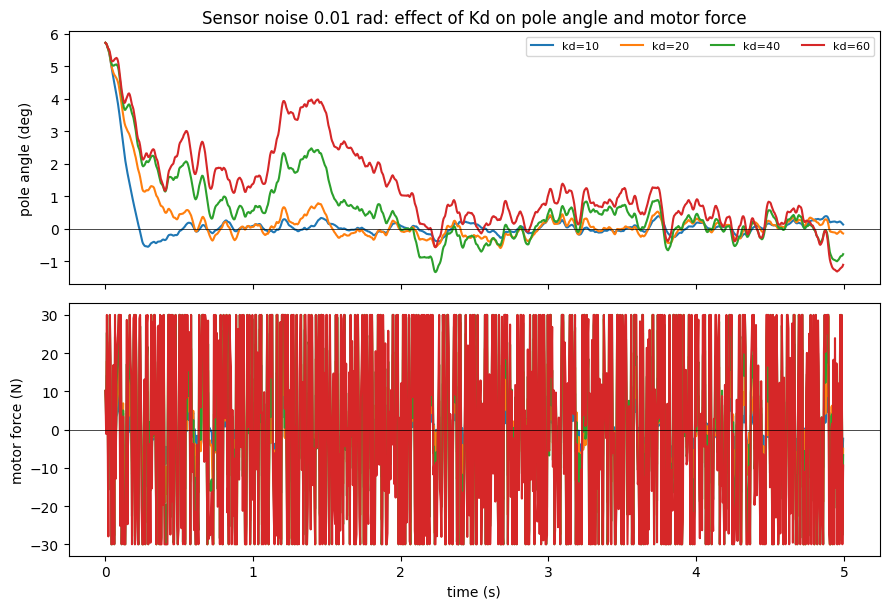

run       fell?   force jitter (N)    effort rms (N)  
kd=10     no      12.29               8.3             
kd=20     no      22.00               14.9            
kd=40     no      31.47               21.6            
kd=60     no      35.09               24.3            


In [ ]:
# ---- Cell 16: Experiment 4, sensor noise vs Kd ----
base = dict(kp=100, ki=1, kd=20)
runs = sweep("kd", [10, 20, 40, 60], base, T=5.0, noise=0.01)
plot_runs(runs, "Sensor noise 0.01 rad: effect of Kd on pole angle and motor force", rows=("angle", "force"))

print(f"{'run':<10}{'fell?':<8}{'force jitter (N)':<20}{'effort rms (N)':<16}")
for label, log in runs:
    jitter = np.std(np.diff(log[:, 4]))          # how much the force jumps from one step to the next
    print(f"{label:<10}{('YES' if log[-1, 5] else 'no'):<8}{jitter:<20.2f}{metrics(log)['effort_rms_N']:<16.1f}")

## Experiment 5: Integrator windup (a null result)

Windup is the idea that, while the motor is saturated, the I term keeps adding up leftover lean that the motor cannot act on yet, and the stored total later causes overshoot. The `i_max` clamp is the guard against this.

The scan below compares `i_max=10` (guard on) with `i_max=1000` (guard effectively off) under a weak motor (6 N or 10 N limit), two Ki values and a sustained shove that is then released.

**Result:** the two settings give identical numbers in every case. Either the pole falls in both runs (the weak motor cannot hold it), or it recovers in both with the same peak lean. On this plant the clamp never binds: the pole is unstable, so it either falls quickly or recovers quickly, and the I total never grows large enough to reach the limit. Windup is real in general, but it is not a visible problem for this cart-pole at these settings, so the clamp stays in the controller as cheap insurance.

In [ ]:
import numpy as np
# windup scan: sustained shove while the motor is weak, then released; compares i_max=10 (guard on) with i_max=1000 (guard off)
for umax in [6.0, 10.0]:
    for ki in [20, 100]:
        for push in [(1.0, 8.0, 3.0), (1.0, 12.0, 3.0)]:
            res = []
            for im in [10, 1000]:
                pid = PID(100, ki, 20, dt=0.005, u_max=umax, i_max=im)
                log = simulate(pid, th0=0.0, T=10.0, push=push)
                th = np.degrees(log[:, 2])
                after = th[int((push[0]+push[2])/0.005):]
                peak = round(float(np.max(np.abs(after))), 1) if len(after) else None
                res.append((im, peak, bool(log[:, 5].max())))
            print(f"umax={umax} ki={ki} push={push}: {res}")

umax=6.0 ki=20 push=(1.0, 8.0, 3.0): [(10, None, True), (1000, None, True)]
umax=6.0 ki=20 push=(1.0, 12.0, 3.0): [(10, None, True), (1000, None, True)]
umax=6.0 ki=100 push=(1.0, 8.0, 3.0): [(10, None, True), (1000, None, True)]
umax=6.0 ki=100 push=(1.0, 12.0, 3.0): [(10, None, True), (1000, None, True)]
umax=10.0 ki=20 push=(1.0, 8.0, 3.0): [(10, 2.8, False), (1000, 2.8, False)]
umax=10.0 ki=20 push=(1.0, 12.0, 3.0): [(10, None, True), (1000, None, True)]
umax=10.0 ki=100 push=(1.0, 8.0, 3.0): [(10, 3.9, False), (1000, 3.9, False)]
umax=10.0 ki=100 push=(1.0, 12.0, 3.0): [(10, None, True), (1000, None, True)]


## Experiment 6: Cart drift

The PID only sees the pole angle, so nothing tells it where the cart is on the track. After catching the initial lean the cart is already moving, and the controller has no reason to bring it back.

Setup: Kp=100, Ki=1, Kd=20, initial lean 0.1 rad, 20 s, no noise. Plot cart position x and pole angle.

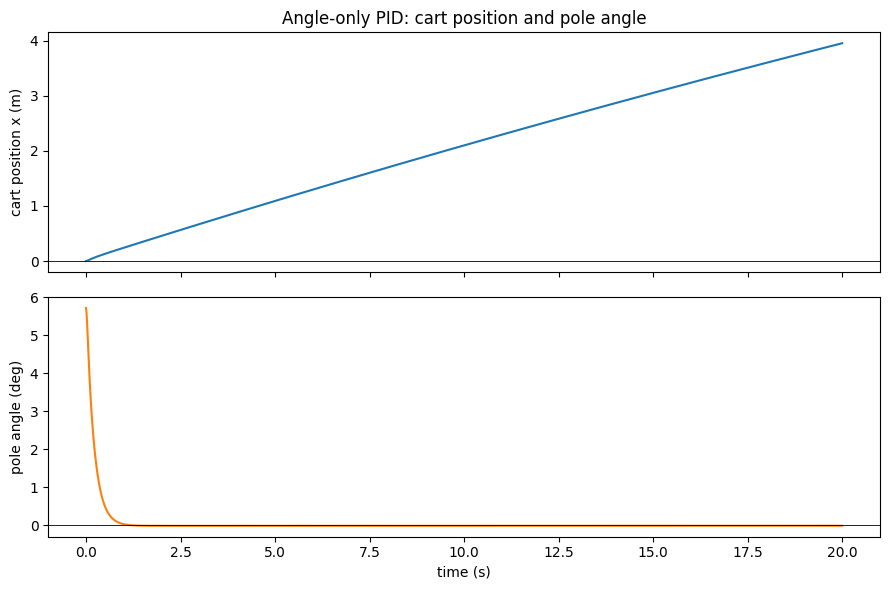

t= 1s  x=   0.24 m  angle=  0.03 deg
t= 5s  x=   1.09 m  angle= -0.01 deg
t=10s  x=   2.10 m  angle= -0.01 deg
t=15s  x=   3.05 m  angle= -0.01 deg
t=20s  x=   3.95 m  angle= -0.01 deg
fell: False


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

pid = PID(100, 1, 20, dt=0.005)
log = simulate(pid, th0=0.1, T=20.0)
t, x, th = log[:, 0], log[:, 1], np.degrees(log[:, 2])

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(t, x); ax[0].axhline(0, color="k", lw=0.6)
ax[0].set_ylabel("cart position x (m)"); ax[0].set_title("Angle-only PID: cart position and pole angle")
ax[1].plot(t, th, color="C1"); ax[1].axhline(0, color="k", lw=0.6)
ax[1].set_ylabel("pole angle (deg)"); ax[1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

for tt in [1, 5, 10, 15, 20]:
    i = min(int(tt / 0.005), len(t) - 1)
    print(f"t={tt:>2}s  x={x[i]:7.2f} m  angle={th[i]:6.2f} deg")
print("fell:", bool(log[:, 5].max()))

## LQR: the fourth controller

LQR uses all four state variables (cart position, cart speed, pole angle, pole angle speed) and computes the gains from the physics instead of tuning them by hand.

1. Linearise the cart-pole around the upright position to get `ds/dt = A s + B u`.
2. Choose a cost: `Q` penalises each state being away from zero, `R` penalises motor effort.
3. Solve the Riccati equation (scipy) for the gain vector `K`. The control law is `u = -K s`.

The gains `K` are computed for one specific robot model. How well they hold up when the real robot differs is part of the robustness study later.

## Robustness study, part 1: random robots

Question: if I tune a controller on one perfect robot, does it still work when the robot changes a bit?

**Random robot.** Each robot is the nominal cart-pole with these parts changed by a random amount:

| part | nominal | random range |
|---|---|---|
| cart mass M | 1.0 kg | x0.4 to x1.6 |
| pole mass m | 0.1 kg | x0.2 to x1.8 |
| pole half-length l | 0.5 m | x0.4 to x1.6 |
| motor strength | 1.0 | x0.4 to x1.6 (force actually delivered) |
| command delay | 0 | 0 to 6 steps (0 to 30 ms) |
| sensor noise | 0 | 0 to 0.01 rad |

**Command delay** means the controller reads the pole angle straight away, but the force it asks for reaches the motor 0 to 30 ms late. (It is not a delay in the sensor. The sensor noise is on the angle reading.)

**Choosing the range.** A first attempt with changes of about +-30% was too gentle: both the hand-tuned PID and the nominal LQR passed all 100 tuning robots, so the study could not tell them apart. Doubling the spread (a factor of 2.0, as above) gives failures for both, which is where the interesting comparison starts.

**Failure** means the pole tilts past 45 degrees, or the cart runs past the end of a 2.5 m track (+-2.5 m), within 10 s. Every robot starts with a 0.1 rad lean.

**Two sets.** Robots with seeds 0 to 99 form the **tuning set**, used to tune controllers. Robots with seeds 1000 to 1499 form the **test set** (500 robots), used only for the final scores. The seeds never overlap, so a controller never sees a test robot during tuning.

In [8]:
from scipy.linalg import solve_continuous_are

def linearize(plant, eps=1e-6):
    """Numerical A, B of ds/dt = A s + B u around the upright equilibrium (s=0, u=0)."""
    s0 = np.zeros(4)
    A = np.zeros((4, 4))
    for i in range(4):
        d = np.zeros(4); d[i] = eps
        A[:, i] = (plant.deriv(s0 + d, 0.0) - plant.deriv(s0 - d, 0.0)) / (2 * eps)
    B = ((plant.deriv(s0, eps) - plant.deriv(s0, -eps)) / (2 * eps)).reshape(4, 1)
    return A, B

def lqr_gain(plant, Q, R):
    A, B = linearize(plant)
    P = solve_continuous_are(A, B, Q, np.array([[R]]))
    return (B.T @ P / R).flatten()          # K = R^-1 B^T P

class LQR:
    """State feedback u = -K s, with the same 30 N motor limit as the PID."""
    def __init__(self, K, u_max=30.0):
        self.K, self.u_max = np.asarray(K), u_max
    def reset(self): pass
    def __call__(self, state):
        return float(np.clip(-self.K @ state, -self.u_max, self.u_max))

def simulate_state(ctrl, th0=0.1, T=20.0, noise_std=0.0, seed=0, plant=None):
    """Like simulate(), but the controller sees the full noisy state. Same log columns."""
    rng = np.random.default_rng(seed)
    cp = plant or CartPole()
    ctrl.reset()
    s = np.array([0.0, 0.0, th0, 0.0])
    n = int(T / cp.dt)
    log = np.zeros((n, 6)); fell = False
    for k in range(n):
        meas = s + rng.normal(0, noise_std, 4) if noise_std else s
        F = ctrl(meas)
        s = cp.step(s, F)
        if abs(s[2]) > np.pi/4: fell = True
        log[k] = [k * cp.dt, s[0], s[2], s[3], F, fell]
        if fell: log = log[:k+1]; break
    return log

Q = np.diag([1.0, 1.0, 10.0, 1.0])   # penalties on x, x_dot, theta, theta_dot
R = 0.1                              # penalty on motor effort
K = lqr_gain(CartPole(), Q, R)
print("LQR gains K [x, x_dot, theta, theta_dot]:", np.round(K, 2))

LQR gains K [x, x_dot, theta, theta_dot]: [ -3.16  -5.91 -49.54 -12.85]


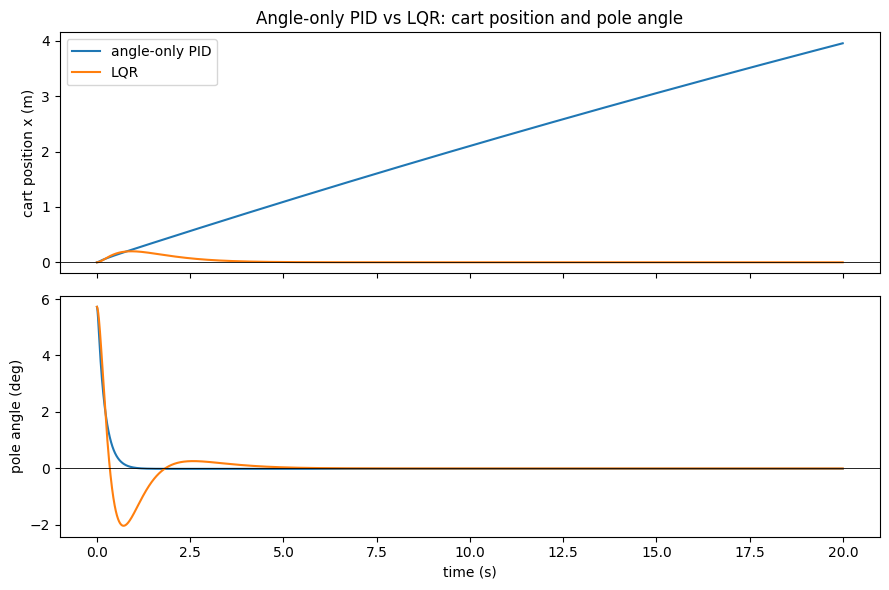

LQR t= 1s  x= 0.198 m  angle=-1.567 deg  F= -0.32 N
LQR t= 5s  x= 0.005 m  angle= 0.040 deg  F=  0.01 N
LQR t=10s  x= 0.000 m  angle= 0.000 deg  F=  0.00 N
LQR t=20s  x= 0.000 m  angle= 0.000 deg  F=  0.00 N
LQR fell: False | max |F| = 5.0 N


In [ ]:
log_lqr = simulate_state(LQR(K), th0=0.1, T=20.0)
pid = PID(100, 1, 20, dt=0.005)
log_pid = simulate(pid, th0=0.1, T=20.0)

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for name, lg in [("angle-only PID", log_pid), ("LQR", log_lqr)]:
    ax[0].plot(lg[:, 0], lg[:, 1], label=name)
    ax[1].plot(lg[:, 0], np.degrees(lg[:, 2]), label=name)
ax[0].axhline(0, color="k", lw=0.6); ax[1].axhline(0, color="k", lw=0.6)
ax[0].set_ylabel("cart position x (m)"); ax[1].set_ylabel("pole angle (deg)"); ax[1].set_xlabel("time (s)")
ax[0].set_title("Angle-only PID vs LQR: cart position and pole angle"); ax[0].legend()
plt.tight_layout(); plt.show()

for tt in [1, 5, 10, 20]:
    i = min(int(tt / 0.005), len(log_lqr) - 1)
    print(f"LQR t={tt:>2}s  x={log_lqr[i,1]:6.3f} m  angle={np.degrees(log_lqr[i,2]):6.3f} deg  F={log_lqr[i,4]:6.2f} N")
print("LQR fell:", bool(log_lqr[:, 5].max()), "| max |F| =", round(float(np.abs(log_lqr[:, 4]).max()), 1), "N")

In [9]:
from collections import deque

SPREAD = 2.0          # how far robots stray from nominal (1.0 = about +-30%); chosen so failures actually occur
NOMINAL = dict(M=1.0, m=0.1, l=0.5)
TRACK_LIMIT = 2.5     # metres

def sample_robot(seed, spread=SPREAD):
    """One random robot, fully determined by its seed."""
    r = np.random.default_rng(seed)
    u = lambda c: max(0.2, 1 + spread * 0.3 * r.uniform(-1, 1) * c)   # multiplier around 1, never below 0.2
    return dict(
        seed=seed,
        M=NOMINAL["M"] * u(1.0),
        m=NOMINAL["m"] * u(1.33),
        l=NOMINAL["l"] * u(1.0),
        gain=max(0.2, 1 + spread * 0.3 * r.uniform(-1, 1)),   # motor strength
        delay=int(r.integers(0, int(round(3 * spread)) + 1)), # command delay: the force reaches the motor this many 5 ms steps late
        noise=r.uniform(0, 0.005 * spread),                    # sensor noise std (rad)
    )

TUNE_SEEDS = list(range(0, 100))        # tuning set: 100 robots
TEST_SEEDS = list(range(1000, 1500))    # test set: 500 robots
NOMINAL_ROBOT = dict(seed=-1, M=1.0, m=0.1, l=0.5, gain=1.0, delay=0, noise=0.0)

def run_robot(ctrl, robot, th0=0.1, T=10.0, dt=0.005):
    """Run one controller on one robot. Returns (log, ok). ok = no fall and stayed on the track."""
    rng = np.random.default_rng(robot["seed"] + 12345)
    cp = CartPole(M=robot["M"], m=robot["m"], l=robot["l"], dt=dt)
    ctrl.reset()
    full_state = hasattr(ctrl, "K")                      # LQR reads all 4 numbers, PID only the angle
    s = np.array([0.0, 0.0, th0, 0.0])
    pipe = deque([0.0] * robot["delay"])                 # command delay: the controller reads the sensor at once, its force command reaches the motor late
    n = int(T / dt); log = np.zeros((n, 6)); ok = True
    for k in range(n):
        noise = rng.normal(0, robot["noise"], 4) if robot["noise"] else np.zeros(4)
        F_cmd = ctrl(s + noise) if full_state else ctrl(s[2] + noise[2])
        pipe.append(F_cmd)
        F = pipe.popleft() * robot["gain"]
        s = cp.step(s, F)
        failed = abs(s[2]) > np.pi / 4 or abs(s[0]) > TRACK_LIMIT
        log[k] = [k * dt, s[0], s[2], s[3], F, failed]
        if failed: ok = False; log = log[:k + 1]; break
    return log, ok

def success_rate(make_ctrl, seeds):
    """Fraction of robots (by seed) on which a freshly built controller does not fail."""
    return float(np.mean([run_robot(make_ctrl(), sample_robot(sd))[1] for sd in seeds]))

make_pid = lambda: PID(100, 1, 20, dt=0.005)     # hand-tuned PID
make_lqr = lambda: LQR(K)                         # LQR designed on the nominal robot

# sanity: the nominal robot must be fine for both controllers
print("nominal robot  PID ok:", run_robot(make_pid(), NOMINAL_ROBOT)[1], "| LQR ok:", run_robot(make_lqr(), NOMINAL_ROBOT)[1])
for sd in range(3):
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in sample_robot(sd).items()})

nominal robot  PID ok: True | LQR ok: True
{'seed': 0, 'M': 1.164, 'm': 0.063, 'l': 0.225, 'gain': 0.42, 'delay': 1, 'noise': 0.009}
{'seed': 1, 'M': 1.014, 'm': 0.172, 'l': 0.286, 'gain': 1.538, 'delay': 1, 'noise': 0.004}
{'seed': 2, 'M': 0.714, 'm': 0.068, 'l': 0.689, 'gain': 0.51, 'delay': 2, 'noise': 0.007}


### First look: nominal controllers on the 100 tuning robots

Neither controller has been tuned for these robots yet: the hand-tuned PID (Kp=100, Ki=1, Kd=20) and the LQR gains from the nominal robot are used as they are. Each dot below is one random robot (pole length vs motor strength); green means the controller kept the pole up and the cart on the track, red means it failed.

hand-tuned PID  success on tuning set:  79.0%  (79/100)
LQR (nominal)   success on tuning set:  93.0%  (93/100)
took 29 s


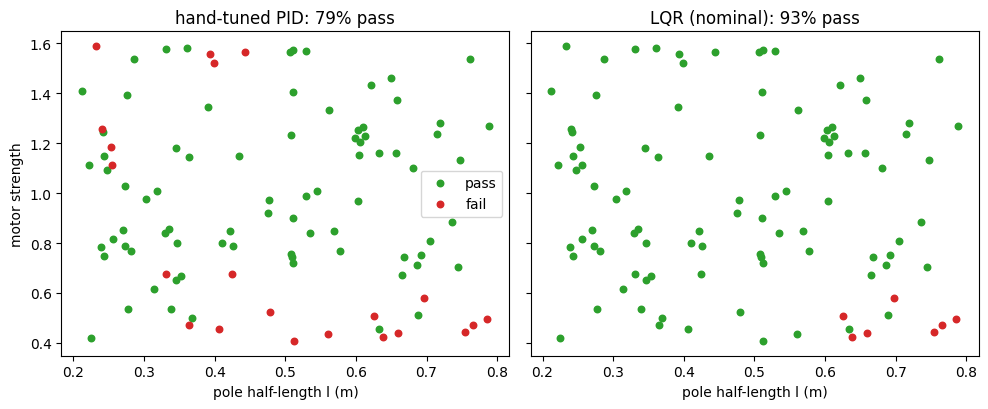

In [ ]:
import time
t0 = time.time()
robots = [sample_robot(sd) for sd in TUNE_SEEDS]
res = {}
for name, mk in [("hand-tuned PID", make_pid), ("LQR (nominal)", make_lqr)]:
    res[name] = np.array([run_robot(mk(), r)[1] for r in robots])
    print(f"{name:15s} success on tuning set: {res[name].mean()*100:5.1f}%  ({res[name].sum()}/{len(robots)})")
print(f"took {time.time()-t0:.0f} s")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for a, (name, ok) in zip(ax, res.items()):
    L = np.array([r["l"] for r in robots]); G = np.array([r["gain"] for r in robots])
    a.scatter(L[ok], G[ok], c="tab:green", label="pass", s=22)
    a.scatter(L[~ok], G[~ok], c="tab:red", label="fail", s=22)
    a.set_title(f"{name}: {ok.mean()*100:.0f}% pass"); a.set_xlabel("pole half-length l (m)")
ax[0].set_ylabel("motor strength"); ax[0].legend()
plt.tight_layout(); plt.show()

## Optuna: letting a program tune the PID

Optuna tries gains (Kp, Ki, Kd), scores each try with a cost function, and uses the scores so far to choose the next gains to try. The cost for one run adds up: pole lean squared, a small penalty on cart position squared, and a tiny penalty on motor effort. A run that fails (pole falls or cart leaves the track) gets a large flat penalty, so the optimizer learns to avoid failures first.

Two tuned PIDs for the study, with the same search space and the same number of trials:

- **PID-perfect:** the cost is measured on the nominal (perfect) robot only.
- **PID-random:** the cost is the average over random tuning robots (domain randomization).

Both are then scored on the same set of robots they were not tuned on.

**A note on reading the cost.** The hand-tuned PID has a much higher cost on the perfect robot (about 0.31, against about 0.005 for PID-perfect). Almost all of that difference is the cart drifting away from the start (the cart term), not the pole leaning more. The pole-lean part is actually similar for both (about 0.001 and 0.002). So the cost mostly rewards "the cart stays near where it started". The cell below prints this split.

In [10]:
%pip install -q optuna
import time
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def episode_cost(ctrl, robot, T=10.0, dt=0.005):
    """Lower is better. Smooth part: lean^2 + 0.02*cart^2 + tiny effort term; failure adds a big flat penalty."""
    log, ok = run_robot(ctrl, robot, T=T, dt=dt)
    th, x, F = log[:, 2], log[:, 1], log[:, 4]
    cost = np.sum(th**2 + 0.02 * x**2 + 1e-5 * F**2) * dt
    if not ok:
        cost += 10.0 + 5.0 * (1 - len(log) * dt / T)    # failing early is worse than failing late
    return cost

def suggest_pid(trial):
    return dict(kp=trial.suggest_float("kp", 20, 300, log=True),
                ki=trial.suggest_float("ki", 0.0, 20.0),
                kd=trial.suggest_float("kd", 1, 60, log=True))

def tune_pid(robots, n_trials, seed=0):
    """Optuna study that minimises the average episode cost of a PID over the given robots."""
    def objective(trial):
        p = suggest_pid(trial)
        return float(np.mean([episode_cost(PID(p["kp"], p["ki"], p["kd"], dt=0.005), r) for r in robots]))
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=n_trials)
    return study

def make_pid_from(params):
    return lambda: PID(params["kp"], params["ki"], params["kd"], dt=0.005)
print("optuna", optuna.__version__, "ready")

optuna 5.1.0 ready


### PID-perfect: Optuna tunes on the nominal robot only

150 trials. Afterwards the best gains are scored on the 100 random tuning robots, next to the hand-tuned PID (79% on the same robots).

In [11]:
t0 = time.time()
study_perfect = tune_pid([NOMINAL_ROBOT], n_trials=150, seed=0)
best_perfect = study_perfect.best_params
print("PID-perfect best gains:", {k: round(v, 2) for k, v in best_perfect.items()},
      "| cost on perfect robot:", round(study_perfect.best_value, 5),
      f"| tuning took {time.time()-t0:.0f} s")
print("hand-tuned PID cost on perfect robot:", round(episode_cost(make_pid(), NOMINAL_ROBOT), 5))

# where does the cost come from? (lean^2, cart^2 and effort parts of the same 10 s run on the perfect robot)
def cost_parts(ctrl, robot, T=10.0, dt=0.005):
    log, ok = run_robot(ctrl, robot, T=T, dt=dt)
    th, x, F = log[:, 2], log[:, 1], log[:, 4]
    return dict(lean=np.sum(th**2) * dt, cart=np.sum(0.02 * x**2) * dt, effort=np.sum(1e-5 * F**2) * dt, x_end=float(x[-1]))
print("\ncost split on the perfect robot:")
for name, mk in [("hand-tuned PID", make_pid), ("PID-perfect", make_pid_from(best_perfect))]:
    p = cost_parts(mk(), NOMINAL_ROBOT)
    print(f"  {name:15s} pole lean {p['lean']:.4f} | cart position {p['cart']:.4f} | effort {p['effort']:.4f} | cart ends {p['x_end']:.2f} m from the start")

hand = success_rate(make_pid, TUNE_SEEDS)
perf = success_rate(make_pid_from(best_perfect), TUNE_SEEDS)
print(f"\nSuccess on the 100 random tuning robots:  hand-tuned {hand*100:.0f}%   |   PID-perfect {perf*100:.0f}%")

PID-perfect best gains: {'kp': 195.59, 'ki': 19.83, 'kd': 2.83} | cost on perfect robot: 0.00508 | tuning took 17 s
hand-tuned PID cost on perfect robot: 0.3069

cost split on the perfect robot:
  hand-tuned PID  pole lean 0.0012 | cart position 0.3057 | effort 0.0000 | cart ends 2.10 m from the start
  PID-perfect     pole lean 0.0016 | cart position 0.0029 | effort 0.0006 | cart ends 0.15 m from the start

Success on the 100 random tuning robots:  hand-tuned 79%   |   PID-perfect 44%


### PID-random: Optuna tunes on random robots

Each trial is scored as the average cost over 30 random robots (seeds 0 to 29 of the tuning set). The study runs in chunks of trials in the next cells so that each run stays short. Afterwards the best gains are scored on all 100 tuning robots.

In [13]:
robots_tune30 = [sample_robot(sd) for sd in TUNE_SEEDS[:30]]

def objective_random(trial):
    p = suggest_pid(trial)
    return float(np.mean([episode_cost(PID(p["kp"], p["ki"], p["kd"], dt=0.005), r) for r in robots_tune30]))

study_random = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=0))
t0 = time.time()
study_random.optimize(objective_random, n_trials=20)
print(f"{len(study_random.trials)} trials done in {time.time()-t0:.0f} s | best cost so far {study_random.best_value:.4f}")
print({k: round(v, 2) for k, v in study_random.best_params.items()})

20 trials done in 65 s | best cost so far 0.0147
{'kp': 63.27, 'ki': 16.0, 'kd': 3.12}


In [18]:
# Continue the same study until it has 150 trials (same budget as PID-perfect). Takes about 8 minutes in total.
t0 = time.time()
while len(study_random.trials) < 150:
    study_random.optimize(objective_random, n_trials=min(10, 150 - len(study_random.trials)))
print(f"{len(study_random.trials)} trials done ({time.time()-t0:.0f} s) | best cost {study_random.best_value:.4f}")
print({k: round(v, 2) for k, v in study_random.best_params.items()})

150 trials 34 s 0.0128
{'kp': 77.31, 'ki': 19.21, 'kd': 3.49}


In [19]:
best_random = study_random.best_params
print("PID-random best gains:", {k: round(v, 2) for k, v in best_random.items()})
print("PID-perfect gains:   ", {k: round(v, 2) for k, v in best_perfect.items()})
print("hand-tuned gains:     {'kp': 100, 'ki': 1, 'kd': 20}")

rand = success_rate(make_pid_from(best_random), TUNE_SEEDS)
print(f"\nSuccess on the 100 random tuning robots:")
print(f"  hand-tuned PID  {hand*100:3.0f}%")
print(f"  PID-perfect     {perf*100:3.0f}%")
print(f"  PID-random      {rand*100:3.0f}%")
print(f"  LQR (nominal)    93%   (from the first look)")

PID-random best gains: {'kp': 77.31, 'ki': 19.21, 'kd': 3.49}
PID-perfect gains:    {'kp': 195.59, 'ki': 19.83, 'kd': 2.83}
hand-tuned gains:     {'kp': 100, 'ki': 1, 'kd': 20}

Success on the 100 random tuning robots:
  hand-tuned PID   79%
  PID-perfect      44%
  PID-random       99%
  LQR (nominal)    93%   (from the first look)


## What makes PID-perfect fail?

PID-perfect (Kp=196, Ki=19.8, Kd=2.8) passes only 44% of the 100 tuning robots. For each robot property, the table below shows how far the average failing robot sits from the average passing robot, in units of that property's spread (a standardised difference: a large number means the property separates failures from passes). Then the failure rate is shown by command delay and by motor-strength group.

In [12]:
robots = [sample_robot(sd) for sd in TUNE_SEEDS]       # the 100 tuning robots
rows = []
for r in robots:
    log, ok = run_robot(make_pid_from(best_perfect)(), r)
    kind = "pass" if ok else ("fell" if abs(log[-1, 2]) > np.pi/4 else "left track")
    rows.append((r, ok, kind))

props = ["M", "m", "l", "gain", "delay", "noise"]
fail = [r for r, ok, _ in rows if not ok]; good = [r for r, ok, _ in rows if ok]
print(f"PID-perfect: {len(good)} pass, {len(fail)} fail  |  how they fail:",
      {k: sum(1 for *_, kd in rows if kd == k) for k in ["fell", "left track"]})
print("(property 'delay' is the command delay, in 5 ms steps)")
print(f"\n{'property':<10}{'pass mean':>11}{'fail mean':>11}{'std. difference':>17}")
allv = {p: np.array([r[p] for r, *_ in rows]) for p in props}
for p in props:
    mg = np.mean([r[p] for r in good]); mf = np.mean([r[p] for r in fail])
    print(f"{p:<10}{mg:>11.3f}{mf:>11.3f}{(mf - mg) / allv[p].std():>+17.2f}")

print("\nfailure rate by command delay (steps of 5 ms):")
for d in sorted(set(allv["delay"])):
    sel = [ok for r, ok, _ in rows if r["delay"] == d]
    print(f"  delay {d} ({d*5:>2} ms): {100*(1-np.mean(sel)):3.0f}% fail  ({len(sel)} robots)")

print("\nfailure rate by motor strength:")
edges = [0, 0.7, 1.0, 1.3, 9]
for lo, hi in zip(edges[:-1], edges[1:]):
    sel = [ok for r, ok, _ in rows if lo <= r["gain"] < hi]
    if sel: print(f"  strength {lo:.1f} to {min(hi,9):.1f}: {100*(1-np.mean(sel)):3.0f}% fail  ({len(sel)} robots)")

PID-perfect: 44 pass, 56 fail  |  how they fail: {'fell': 53, 'left track': 3}
(property 'delay' is the command delay, in 5 ms steps)

property    pass mean  fail mean  std. difference
M               1.078      1.036            -0.13
m               0.101      0.109            +0.18
l               0.505      0.462            -0.26
gain            0.960      0.980            +0.06
delay           0.886      4.411            +1.72
noise           0.005      0.005            +0.04

failure rate by command delay (steps of 5 ms):
  delay 0 ( 0 ms):   0% fail  (18 robots)
  delay 1 ( 5 ms):   0% fail  (14 robots)
  delay 2 (10 ms):   8% fail  (12 robots)
  delay 3 (15 ms):  94% fail  (17 robots)
  delay 4 (20 ms): 100% fail  (13 robots)
  delay 5 (25 ms): 100% fail  (11 robots)
  delay 6 (30 ms): 100% fail  (15 robots)

failure rate by motor strength:
  strength 0.0 to 0.7:  58% fail  (24 robots)
  strength 0.7 to 1.0:  60% fail  (30 robots)
  strength 1.0 to 1.3:  41% fail  (27 robots)
  

## The scoreboard: all four controllers on the 500 test robots

None of these robots (seeds 1000 to 1499) was used for tuning or for choosing anything else. A controller passes a robot if the pole stays within 45 degrees and the cart stays on the 2.5 m track for 10 s. Each score comes with a 95% Wilson confidence interval (the plausible range for the true pass rate, given 500 robots).

The four controllers:

- **hand-tuned PID** (Kp=100, Ki=1, Kd=20)
- **PID-perfect** (Optuna, nominal robot only)
- **PID-random** (Optuna, random robots)
- **LQR** (gains computed from the nominal robot's equations)

**Not an equal fight.** The three PIDs read only the pole angle. LQR reads four numbers: cart position, cart speed, pole angle and pole speed. So LQR is a reference point, not a like-for-like competitor. Also, PID-random and LQR have overlapping 95% intervals, so read them as "about the same", not "better".

In [20]:
best_random = study_random.best_params
test_robots = [sample_robot(sd) for sd in TEST_SEEDS]
controllers = {
    "hand-tuned PID": make_pid,
    "PID-perfect":    make_pid_from(best_perfect),
    "PID-random":     make_pid_from(best_random),
    "LQR":            make_lqr,
}
if "test_ok" not in globals(): test_ok = {}            # cache: re-running this cell skips finished controllers

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z*z/n
    c = (p + z*z/(2*n)) / d; h = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / d
    return c - h, c + h

t0 = time.time()
for name, mk in controllers.items():
    if name not in test_ok and time.time() - t0 < 150:   # stop starting new controllers after 150 s; just re-run
        test_ok[name] = np.array([run_robot(mk(), r)[1] for r in test_robots])
        print(f"  {name} finished ({time.time()-t0:.0f} s)")

if len(test_ok) == len(controllers):
    print(f"\n{'controller':<16}{'passed':>8}{'pass rate':>11}{'95% interval':>18}")
    for name in controllers:
        k = int(test_ok[name].sum()); lo, hi = wilson(k, len(test_robots))
        print(f"{name:<16}{k:>4}/{len(test_robots)}{100*k/len(test_robots):>10.1f}%   {100*lo:5.1f}% to {100*hi:5.1f}%")
else:
    print("not all controllers finished yet: run this cell again")

  hand-tuned PID finished (55 s)
  PID-perfect finished (88 s)
  PID-random finished (148 s)
  LQR finished (204 s)

controller        passed  pass rate      95% interval
hand-tuned PID   421/500      84.2%    80.7% to  87.1%
PID-perfect      216/500      43.2%    38.9% to  47.6%
PID-random       496/500      99.2%    98.0% to  99.7%
LQR              489/500      97.8%    96.1% to  98.8%


## Results: CSV, table and chart

This cell writes one row per test robot (its parameters and whether each controller passed) to `results/test_results.csv`, prints the summary table, and saves a two-panel chart to `results/pass_rates.png`.

- **Left panel:** overall pass rate of each controller on the 500 test robots, with 95% Wilson confidence intervals.
- **Right panel:** the same, split by command delay (0 to 10 ms vs 15 to 30 ms), since delay was the property that broke PID-perfect.

wrote results/test_results.csv: 500 rows

| controller | pass rate (all 500) | 95% interval | command delay 0-10 ms (n=226) | command delay 15-30 ms (n=274) |
|---|---|---|---|---|
| hand-tuned PID | 84.2% | 80.7% to 87.1% | 91.6% | 78.1% |
| PID-perfect | 43.2% | 38.9% to 47.6% | 95.6% | 0.0% |
| PID-random | 99.2% | 98.0% to 99.7% | 100.0% | 98.5% |
| LQR | 97.8% | 96.1% to 98.8% | 98.2% | 97.4% |


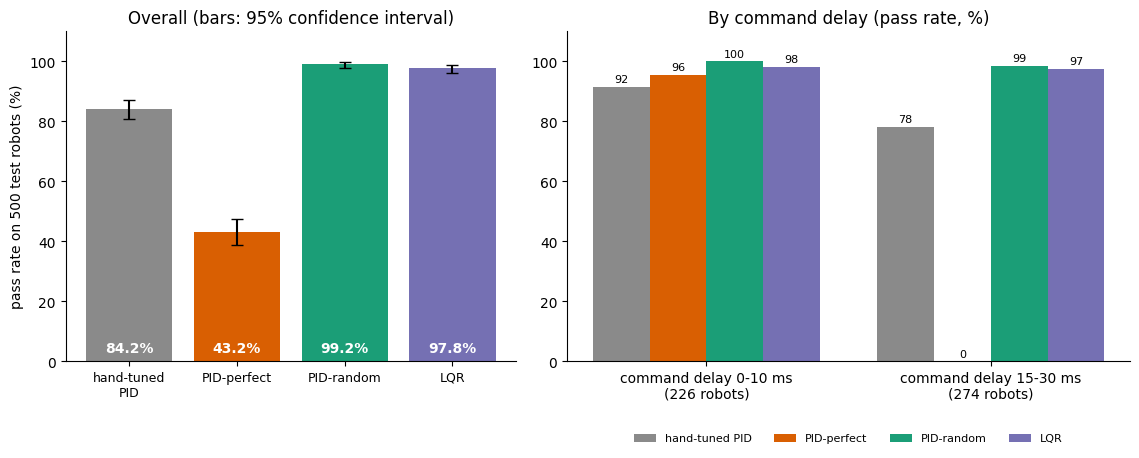

saved results/pass_rates.png; ['pass_rates.png', 'test_results.csv']


In [21]:
import os, csv
os.makedirs("results", exist_ok=True)
names = list(controllers)

# ---- 1. one row per test robot ----
with open("results/test_results.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["seed", "cart_mass_kg", "pole_mass_kg", "pole_half_length_m", "motor_strength",
                "command_delay_ms", "sensor_noise_rad"] + [f"pass_{n.replace(' ', '_').replace('-', '_')}" for n in names])
    for i, r in enumerate(test_robots):
        w.writerow([r["seed"], round(r["M"], 4), round(r["m"], 4), round(r["l"], 4), round(r["gain"], 4),
                    r["delay"] * 5, round(r["noise"], 5)] + [int(test_ok[n][i]) for n in names])
print("wrote results/test_results.csv:", len(test_robots), "rows")

# ---- 2. summary table (markdown, ready for the README) ----
delay_ms = np.array([r["delay"] * 5 for r in test_robots])
low, high = delay_ms <= 10, delay_ms >= 15
print(f"\n| controller | pass rate (all 500) | 95% interval | command delay 0-10 ms (n={low.sum()}) | command delay 15-30 ms (n={high.sum()}) |")
print("|---|---|---|---|---|")
for n in names:
    ok = test_ok[n]; k = int(ok.sum()); lo, hi = wilson(k, len(ok))
    print(f"| {n} | {100*k/len(ok):.1f}% | {100*lo:.1f}% to {100*hi:.1f}% | {100*ok[low].mean():.1f}% | {100*ok[high].mean():.1f}% |")

# ---- 3. chart ----
colors = {"hand-tuned PID": "#8a8a8a", "PID-perfect": "#d95f02", "PID-random": "#1b9e77", "LQR": "#7570b3"}
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw=dict(width_ratios=[1, 1.25]))
x = np.arange(len(names))
rates = np.array([test_ok[n].mean() * 100 for n in names])
ci = np.array([wilson(int(test_ok[n].sum()), len(test_robots)) for n in names]) * 100
ax[0].bar(x, rates, color=[colors[n] for n in names], yerr=[rates - ci[:, 0], ci[:, 1] - rates], capsize=4)
for xi, r in zip(x, rates): ax[0].text(xi, 3, f"{r:.1f}%", ha="center", color="white", fontweight="bold")
ax[0].set_xticks(x); ax[0].set_xticklabels([n.replace(" ", "\n") for n in names], fontsize=9)
ax[0].set_ylim(0, 110); ax[0].set_ylabel("pass rate on 500 test robots (%)")
ax[0].set_title("Overall (bars: 95% confidence interval)")

wbar = 0.2
for j, n in enumerate(names):
    vals = [test_ok[n][low].mean() * 100, test_ok[n][high].mean() * 100]
    xs = np.arange(2) + (j - 1.5) * wbar
    ax[1].bar(xs, vals, wbar, label=n, color=colors[n])
    for xi, v in zip(xs, vals):                                    # print every value, so a 0% bar is not mistaken for missing data
        ax[1].text(xi, v + 1.5, f"{v:.0f}", ha="center", fontsize=8)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels([f"command delay 0-10 ms\n({low.sum()} robots)", f"command delay 15-30 ms\n({high.sum()} robots)"])
ax[1].set_ylim(0, 110); ax[1].set_title("By command delay (pass rate, %)")
ax[1].legend(fontsize=8, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.28), frameon=False)
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("results/pass_rates.png", dpi=150, bbox_inches="tight"); plt.show()
print("saved results/pass_rates.png;", os.listdir("results"))